# **Step 3 of 7: Hierarchical (Agglomerative) Clustering (HR Employees)**

**Agglomerative clustering** starts with every employee as its own cluster and repeatedly **merges the two closest clusters** until only one is left. The full history of merges is the **dendrogram** (a tree). Cutting the tree at a chosen height gives the clusters. You do **not** need to know k in advance.

How "closest" is measured = **linkage**:
- `ward`: merge the pair that increases the within-cluster variance the least (compact, similar-size clusters)
- `complete`: distance between the **farthest** points (compact clusters)
- `average`: average distance between all pairs
- `single`: distance between the **nearest** points (can create long chains)

Good for: seeing the structure at all levels, small / medium data. Weak for: big data (slow, needs all pairwise distances), no `predict` for new points.

### 1. Import and load the preprocessed data
This notebook uses the files made in **step 1 (01_HR_Data_Preprocessing)**:
- `hr_clean.csv`: cleaned data in original units (used to describe the clusters)
- `hr_preprocessed.csv`: scaled clustering features (used by the algorithm)
- `hr_scaler.pkl`, `preprocessing_info.json` (and `hr_truth.csv`, demo data only)

Keep these files in the same folder as this notebook.

> The data is **synthetic demo data** (about 4 hidden employee groups + 3% unusual employees). Because we know the hidden groups, the result can also be checked with *external* metrics. With real HR data this check is not possible and only the internal metrics are used.

In [1]:
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
sns.set_theme(style='whitegrid')

# ---- files made by 01_HR_Data_Preprocessing.ipynb (keep them in the same folder) ----
need = ['hr_clean.csv', 'hr_preprocessed.csv', 'preprocessing_info.json', 'hr_scaler.pkl']
missing = [f for f in need if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f'Run 01_HR_Data_Preprocessing.ipynb first. Missing files: {missing}')

info = json.load(open('preprocessing_info.json'))
FEATURES, PROFILE_COLS = info['features'], info['profile_cols']

df = pd.read_csv('hr_clean.csv')                    # cleaned data, original units (used to describe the clusters)
X_df = pd.read_csv('hr_preprocessed.csv')           # scaled features (used by the algorithm)
assert (df['employee_id'].values == X_df['employee_id'].values).all(), 'files do not match'
X = X_df[FEATURES].values
scaler = joblib.load('hr_scaler.pkl')               # needed to prepare NEW employees

# hidden true groups: exist only in the synthetic demo data, used only to check the result at the end
if os.path.exists('hr_truth.csv'):
    df = df.merge(pd.read_csv('hr_truth.csv'), on='employee_id', how='left')
HAS_TRUTH = 'segment_true' in df.columns

print('Employees:', X.shape[0], '| clustering features:', FEATURES)
print('Hopkins statistic from step 1:', info['hopkins'], '| hidden truth available:', HAS_TRUTH)
df.head()

Employees: 1498 | clustering features: ['satisfaction_level', 'last_evaluation', 'number_project', 'average_monthly_hours', 'time_spend_company']
Hopkins statistic from step 1: 0.747 | hidden truth available: True


,employee_id,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,work_accident,promotion_last_5years,department,left,is_outlier_iqr,segment_true
0,1456,0.87,0.92,4.0,178.0,5.0,1,1,0,technical,0,0,Engaged high performers
1,1957,0.62,0.68,5.0,150.0,10.0,1,1,1,technical,0,0,Loyal long-tenure
2,1612,0.71,0.93,5.0,191.0,4.0,1,0,0,sales,1,0,Engaged high performers
3,1998,0.64,0.73,3.0,180.0,9.0,1,0,0,support,0,0,Loyal long-tenure
4,2037,0.35,0.51,2.0,169.0,2.0,2,0,0,sales,0,0,Disengaged underused


Helper functions used in all sections (metrics, plots, cluster profile):

In [2]:
def internal_metrics(X, labels):
    """Internal metrics (no true labels needed). Noise points (-1) are ignored."""
    labels = np.asarray(labels); mask = labels != -1
    n_clusters = len(set(labels[mask]))
    out = {'n_clusters': n_clusters, 'noise_%': round(100 * (~mask).mean(), 1),
           'silhouette': np.nan, 'calinski_harabasz': np.nan, 'davies_bouldin': np.nan}
    if n_clusters >= 2 and mask.sum() > n_clusters:
        out['silhouette'] = silhouette_score(X[mask], labels[mask])
        out['calinski_harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
        out['davies_bouldin'] = davies_bouldin_score(X[mask], labels[mask])
    return out

def external_metrics(truth, labels):
    """External metrics: compare with the hidden true segments (demo data only)."""
    h, c, v = homogeneity_completeness_v_measure(truth, labels)
    return {'ARI': adjusted_rand_score(truth, labels), 'NMI': normalized_mutual_info_score(truth, labels),
            'homogeneity': h, 'completeness': c, 'v_measure': v}

def plot_clusters(Z, labels, ax, title, centers=None):
    """2D scatter of the clusters (Z = PCA coordinates). Noise = black x."""
    labels = np.asarray(labels); palette = sns.color_palette('tab10', 10)
    for lab in sorted(set(labels)):
        m = labels == lab
        if lab == -1:
            ax.scatter(Z[m, 0], Z[m, 1], c='black', marker='x', s=25, label=f'Noise ({m.sum()})')
        else:
            ax.scatter(Z[m, 0], Z[m, 1], s=16, alpha=0.7, color=palette[lab % 10], label=f'Cluster {lab} ({m.sum()})')
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centers')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title(title); ax.legend(fontsize=8)

def cluster_profile(data, labels):
    """Average of every feature in each cluster (original units) + size."""
    labels = np.asarray(labels)
    prof = data[PROFILE_COLS].assign(cluster=labels).groupby('cluster').mean()
    prof['size'] = pd.Series(labels).value_counts().sort_index()
    prof['share_%'] = (100 * prof['size'] / len(labels)).round(1)
    return prof

def plot_profile(prof, title='Cluster profile (colour = high / low compared with other clusters, number = real average)'):
    feat = prof[PROFILE_COLS]
    z = (feat - feat.mean()) / (feat.std(ddof=0) + 1e-9)
    plt.figure(figsize=(9, 0.9 * len(prof) + 2))
    sns.heatmap(z, annot=feat.round(2), fmt='g', cmap='RdYlGn', center=0, cbar_kws={'label': 'relative level'})
    plt.title(title); plt.ylabel('Cluster'); plt.tight_layout(); plt.show()

### 2. Look at the data

In [3]:
df[PROFILE_COLS].describe().round(2)

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level
count,1498.00,1498.00,1498.00,1498.00,1498.00,1498.00
mean,0.55,0.73,4.12,196.67,4.76,0.93
std,0.23,0.16,1.45,47.51,2.24,0.74
min,0.09,0.36,2.00,96.00,2.00,0.00
25%,0.35,0.60,3.00,160.00,3.00,0.00
50%,0.57,0.77,4.00,191.00,4.00,1.00
75%,0.76,0.86,5.00,222.00,6.00,1.00
max,1.00,1.00,7.00,310.00,10.00,2.00


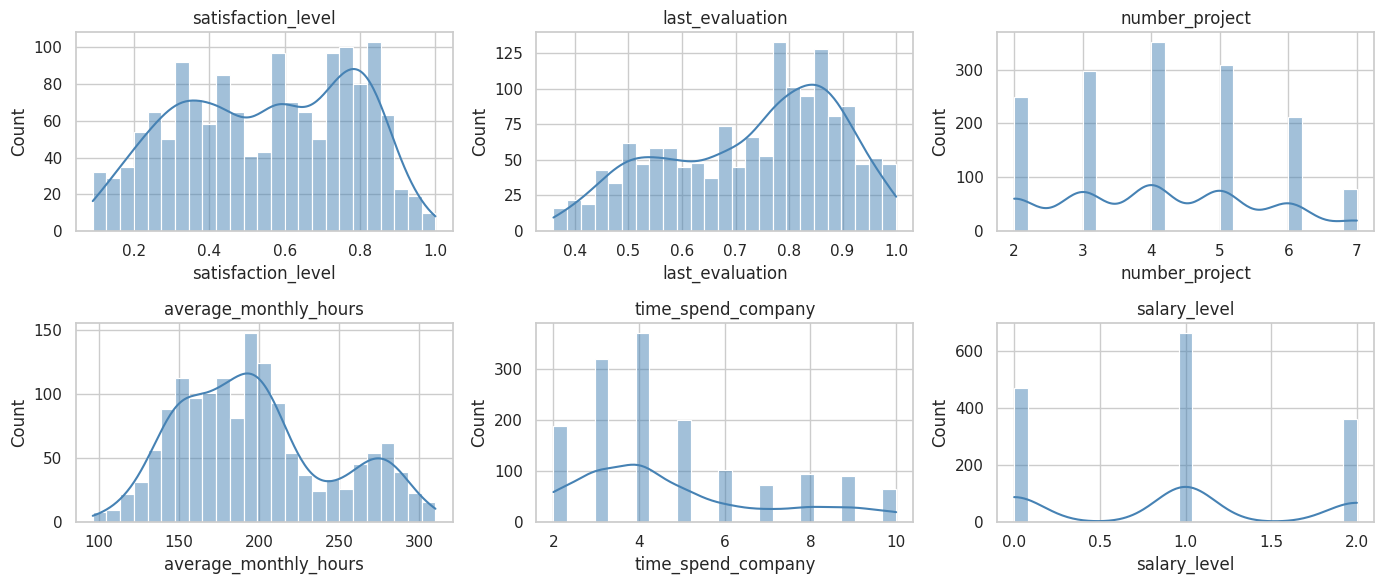

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, f in zip(ax.ravel(), PROFILE_COLS):
    sns.histplot(df[f], bins=25, kde=True, ax=a, color='steelblue')
    a.set_title(f)
plt.tight_layout(); plt.show()

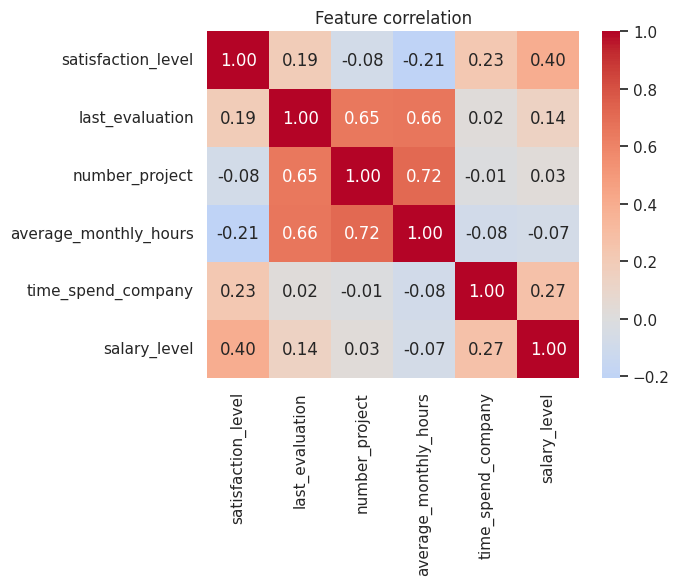

In [5]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[PROFILE_COLS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlation'); plt.show()

### 3. 2D view for plotting (PCA)
The data is already **cleaned and scaled in step 1**, so no preprocessing is needed here. PCA is used **only to draw** the clusters in 2D (the clustering itself uses all features).

In [6]:
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
print('Variance explained by the 2 plotted components:', (pca.explained_variance_ratio_.sum() * 100).round(1), '%')

Variance explained by the 2 plotted components: 72.9 %


### 4. Compare linkage methods
- **Cophenetic correlation** (0 to 1, higher is better): how well the dendrogram keeps the real distances between employees.
- **Silhouette** at the best k (k = 2 to 10).

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import AgglomerativeClustering

dist = pdist(X)
rows, Zs = [], {}
for method in ['ward', 'complete', 'average', 'single']:
    Zl = linkage(X, method=method); Zs[method] = Zl
    coph, _ = cophenet(Zl, dist)
    sils = {k: silhouette_score(X, fcluster(Zl, k, 'maxclust')) for k in range(2, 11) if len(set(fcluster(Zl, k, 'maxclust'))) > 1}
    best_k_m = max(sils, key=sils.get)
    rows.append({'linkage': method, 'cophenetic_corr': coph, 'best_k': best_k_m, 'silhouette': sils[best_k_m]})
link_df = pd.DataFrame(rows).set_index('linkage')
display(link_df.round(3))

LINKAGE = link_df['silhouette'].idxmax()         # change to 'ward' etc. if you want another method
print('Linkage used:', LINKAGE)

,cophenetic_corr,best_k,silhouette
linkage,,,
ward,0.784,5,0.470
complete,0.720,5,0.381
average,0.821,10,0.437
single,0.320,2,0.283


Linkage used: ward


### 5. Choose the number of clusters k
Silhouette, Calinski-Harabasz and Davies-Bouldin for k = 2 to 10, using the chosen linkage.

,silhouette,calinski_harabasz,davies_bouldin
k,,,
2,0.357,756.300,0.945
3,0.437,1143.324,0.861
4,0.465,1411.856,0.883
5,0.470,1147.070,1.097
6,0.373,982.232,1.369
7,0.322,875.578,1.631
8,0.309,784.245,1.627
9,0.304,713.333,1.656
10,0.229,655.750,1.757


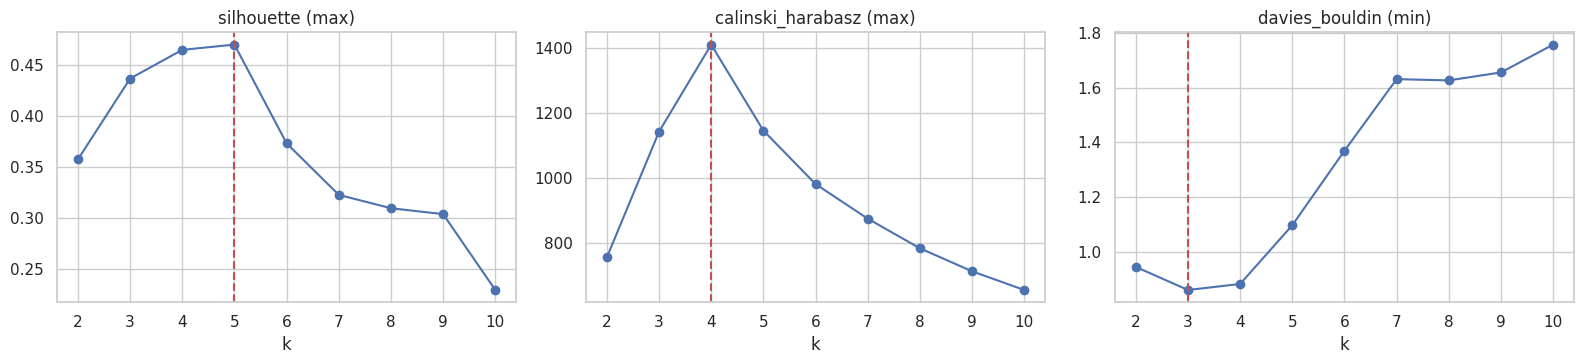

Best k (silhouette): 5


In [8]:
Zl = Zs[LINKAGE]
rows = []
for k in range(2, 11):
    lab = fcluster(Zl, k, 'maxclust') - 1
    m = internal_metrics(X, lab)
    rows.append({'k': k, 'silhouette': m['silhouette'], 'calinski_harabasz': m['calinski_harabasz'], 'davies_bouldin': m['davies_bouldin']})
k_df = pd.DataFrame(rows).set_index('k')
display(k_df.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, col, better in zip(ax, k_df.columns, ['max', 'max', 'min']):
    a.plot(k_df.index, k_df[col], 'o-'); a.set_title(f'{col} ({better})'); a.set_xlabel('k')
    a.axvline(k_df[col].idxmax() if better == 'max' else k_df[col].idxmin(), color='r', ls='--')
plt.tight_layout(); plt.show()

best_k = int(k_df['silhouette'].idxmax())        # change best_k if you prefer another k
print('Best k (silhouette):', best_k)

### 6. Dendrogram
Each vertical line is a merge; its height = the distance at which the merge happened. We cut the tree with the **red line**: all branches below it are the clusters. A good cut is where a tall gap exists between merges. (The tree is shown truncated to the last 30 merges.)

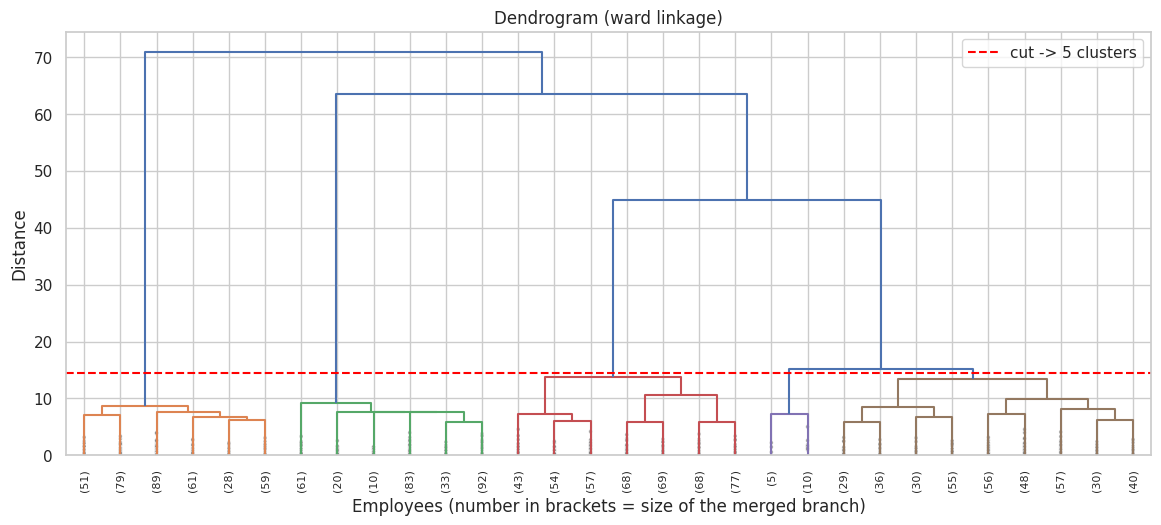

In [9]:
cut_height = (Zl[-(best_k - 1), 2] + Zl[-best_k, 2]) / 2

plt.figure(figsize=(14, 5.5))
dendrogram(Zl, truncate_mode='lastp', p=30, color_threshold=cut_height, leaf_rotation=90, leaf_font_size=8, show_contracted=True)
plt.axhline(cut_height, color='red', ls='--', label=f'cut -> {best_k} clusters')
plt.title(f'Dendrogram ({LINKAGE} linkage)'); plt.xlabel('Employees (number in brackets = size of the merged branch)'); plt.ylabel('Distance')
plt.legend(); plt.show()

### 7. Final Hierarchical model

In [10]:
hc = AgglomerativeClustering(n_clusters=best_k, linkage=LINKAGE).fit(X)
labels = hc.labels_
print('k =', best_k, '| linkage =', LINKAGE)
print(pd.Series(labels).value_counts().sort_index().rename('employees').to_string())

k = 5 | linkage = ward
0    436
1    381
2    299
3    367
4     15


### 8. Evaluation metrics

In [11]:
metrics = internal_metrics(X, labels)
print('===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====')
print('Clusters found     :', metrics['n_clusters'], '| noise points:', metrics['noise_%'], '%')
print('Silhouette         :', round(metrics['silhouette'], 4), ' (higher is better)')
print('Calinski-Harabasz  :', round(metrics['calinski_harabasz'], 1), ' (higher is better)')
print('Davies-Bouldin     :', round(metrics['davies_bouldin'], 4), ' (lower is better)')

if HAS_TRUTH:
    ext = external_metrics(df['segment_true'], labels)
    print('\n===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====')
    for k_, v_ in ext.items():
        print(f'{k_:<13}: {v_:.4f}')

===== INTERNAL METRICS (no true labels needed; noise points are ignored) =====
Clusters found     : 5 | noise points: 0.0 %
Silhouette         : 0.4699  (higher is better)
Calinski-Harabasz  : 1147.1  (higher is better)
Davies-Bouldin     : 1.0972  (lower is better)

===== EXTERNAL METRICS (compared with the hidden true groups, demo data only) =====
ARI          : 0.9059
NMI          : 0.8793
homogeneity  : 0.8643
completeness : 0.8948
v_measure    : 0.8793


**All linkage methods side by side** (same k) to see how much the choice of linkage matters:

In [12]:
rows = []
for method in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=best_k, linkage=method).fit_predict(X)
    r = {'linkage': method, **{k_: v_ for k_, v_ in internal_metrics(X, lab).items() if k_ != 'noise_%'}, 'smallest_cluster': pd.Series(lab).value_counts().min()}
    if HAS_TRUTH: r['ARI'] = adjusted_rand_score(df['segment_true'], lab)
    rows.append(r)
display(pd.DataFrame(rows).set_index('linkage').round(3))
print('single linkage often gives one huge cluster + tiny clusters (the chaining effect).')

,n_clusters,silhouette,calinski_harabasz,davies_bouldin,smallest_cluster,ARI
linkage,,,,,,
ward,5,0.470,1147.070,1.097,15,0.906
complete,5,0.381,863.690,1.221,11,0.704
average,5,0.428,608.279,0.977,3,0.638
single,5,0.045,4.025,0.883,1,0.006


single linkage often gives one huge cluster + tiny clusters (the chaining effect).


### 9. Visualization

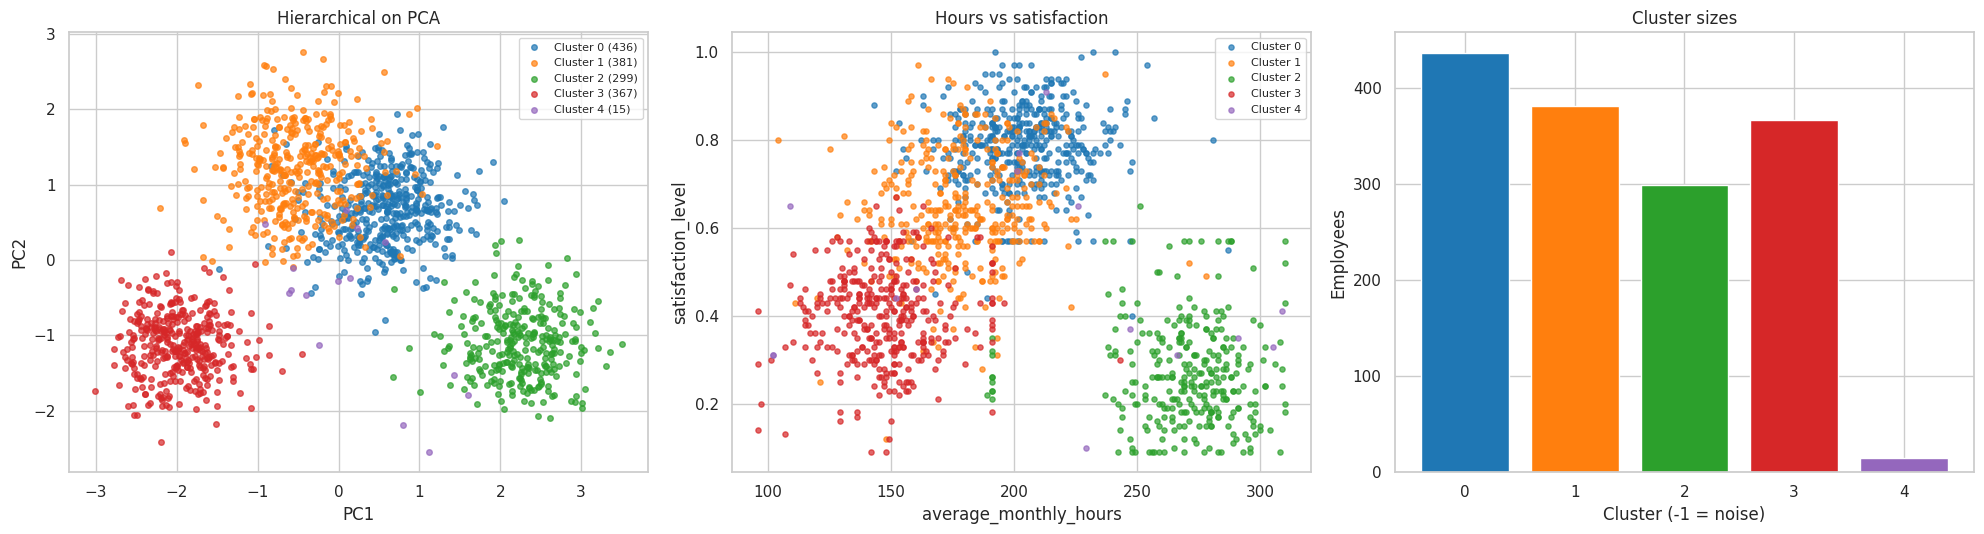

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
plot_clusters(Z, labels, ax[0], 'Hierarchical on PCA')

for c in sorted(set(labels)):
    m = labels == c
    ax[1].scatter(df.loc[m, 'average_monthly_hours'], df.loc[m, 'satisfaction_level'], s=14, alpha=0.7,
                  color='black' if c == -1 else sns.color_palette('tab10')[c % 10], marker='x' if c == -1 else 'o',
                  label='Noise' if c == -1 else f'Cluster {c}')
ax[1].set_xlabel('average_monthly_hours'); ax[1].set_ylabel('satisfaction_level'); ax[1].set_title('Hours vs satisfaction'); ax[1].legend(fontsize=8)

sizes = pd.Series(labels).value_counts().sort_index()
ax[2].bar(sizes.index.astype(str), sizes.values, color=['black' if i == -1 else sns.color_palette('tab10')[i % 10] for i in sizes.index])
ax[2].set_xlabel('Cluster (-1 = noise)'); ax[2].set_ylabel('Employees'); ax[2].set_title('Cluster sizes')
plt.tight_layout(); plt.show()

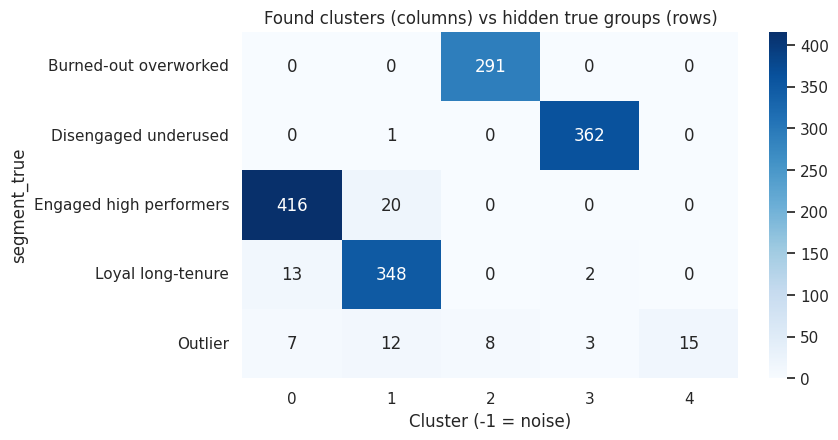

In [14]:
if HAS_TRUTH:
    plt.figure(figsize=(8, 4.5))
    sns.heatmap(pd.crosstab(df['segment_true'], labels), annot=True, fmt='d', cmap='Blues')
    plt.title('Found clusters (columns) vs hidden true groups (rows)'); plt.xlabel('Cluster (-1 = noise)'); plt.show()

**Clustermap:** a heatmap of 300 random employees, rows ordered by the hierarchical tree; the colour bar on the left = cluster. You can see the groups as blocks of similar colours.

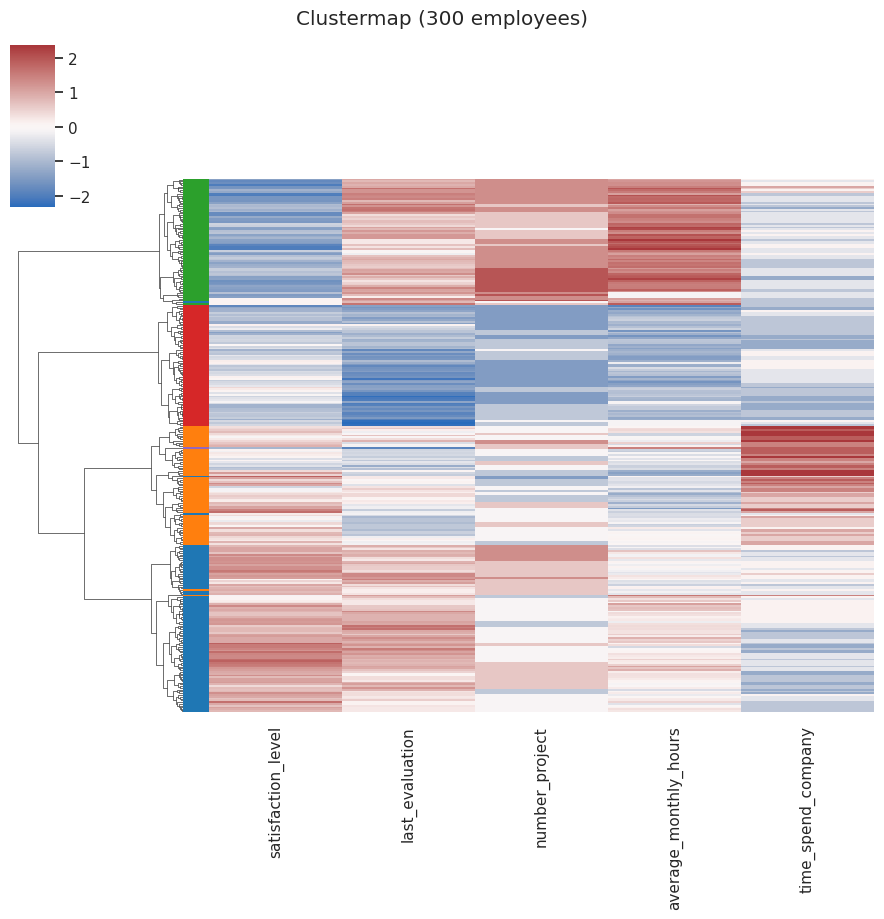

In [15]:
sample = df.sample(300, random_state=1).index
pal = dict(zip(range(best_k), sns.color_palette('tab10', best_k)))
g = sns.clustermap(pd.DataFrame(X, columns=FEATURES).loc[sample], method=LINKAGE, col_cluster=False, cmap='vlag', center=0,
                   row_colors=pd.Series(labels, index=range(len(X))).loc[sample].map(pal).values, figsize=(9, 9),
                   yticklabels=False)
g.fig.suptitle('Clustermap (300 employees)', y=1.02); plt.show()

### Cluster profile: who is in each cluster?
Green = high, red = low compared with the other clusters. Cluster -1 (if present) = noise / unusual employees.

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,salary_level,size,share_%
cluster,,,,,,,,
0,0.79,0.84,4.45,203.56,3.85,1.21,436,29.1
1,0.65,0.71,3.79,178.35,7.99,1.32,381,25.4
2,0.27,0.88,5.98,270.37,3.94,0.52,299,20.0
3,0.40,0.52,2.44,147.01,3.14,0.53,367,24.5
4,0.47,0.48,6.33,207.60,4.87,0.87,15,1.0


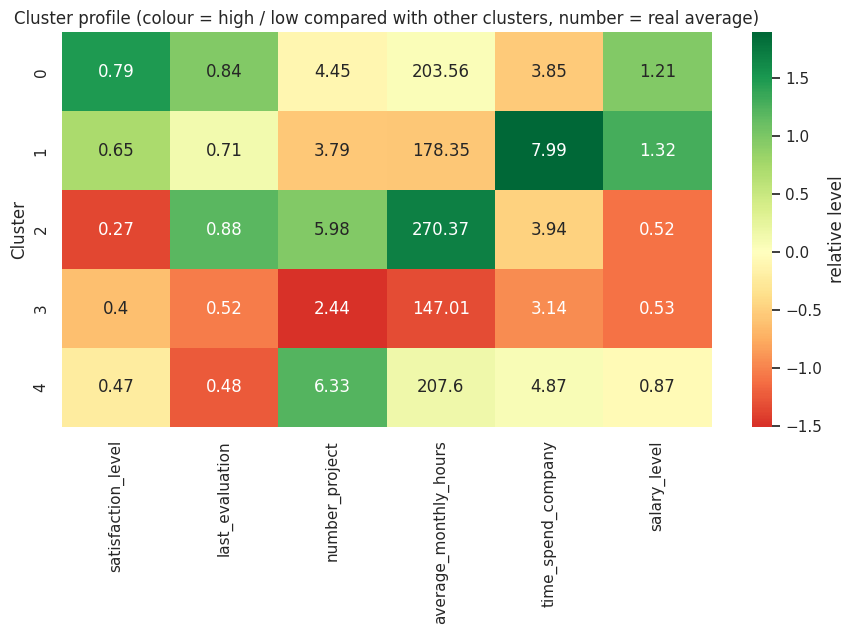

In [16]:
prof = cluster_profile(df, labels)
display(prof.round(2))
plot_profile(prof)

In [17]:
small = prof[prof['share_%'] < 3]
if len(small):
    print('Very small cluster(s):', {int(i): int(r['size']) for i, r in small.iterrows()})
    print('A very small cluster usually holds UNUSUAL employees (outliers) that the algorithm had to group somewhere.')
    print('Check its profile above: it is a list of special cases, not a real segment.')
else:
    print('No very small cluster (all clusters have at least 3% of the employees).')

Very small cluster(s): {4: 15}
A very small cluster usually holds UNUSUAL employees (outliers) that the algorithm had to group somewhere.
Check its profile above: it is a list of special cases, not a real segment.


### Assign new employees and save
This algorithm has no `predict` method for new data. A common solution: train a small **KNN classifier on the found cluster labels** and use it to place new employees in the nearest cluster.

In [18]:
mask = labels != -1
assigner = KNeighborsClassifier(n_neighbors=5).fit(X[mask], labels[mask])

new = pd.DataFrame({'satisfaction_level': [0.15, 0.85, 0.45], 'last_evaluation': [0.90, 0.88, 0.50],
                    'number_project': [7, 5, 2], 'average_monthly_hours': [280, 210, 140],
                    'time_spend_company': [4, 3, 3]})
new['cluster'] = assigner.predict(scaler.transform(new[FEATURES]))
display(new)

joblib.dump({'scaler': scaler, 'model': hc, 'assigner': assigner, 'features': FEATURES, 'profile': prof}, 'hierarchical_hr_model.pkl')
df.assign(cluster=labels).to_csv('hr_hierarchical_clusters.csv', index=False)
print('Saved: hierarchical_hr_model.pkl, hr_hierarchical_clusters.csv')

,satisfaction_level,last_evaluation,number_project,average_monthly_hours,time_spend_company,cluster
0,0.15,0.90,7,280,4,2
1,0.85,0.88,5,210,3,0
2,0.45,0.50,2,140,3,3


Saved: hierarchical_hr_model.pkl, hr_hierarchical_clusters.csv


### Download (Google Colab only)

In [19]:
try:
    from google.colab import files
    files.download('hierarchical_hr_model.pkl'); files.download('hr_hierarchical_clusters.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
